# 14b — Three-dimensional growth on the BrainWeb phantom

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/brains-to-models/blob/main/code/notebooks/14b_brainweb_growth.ipynb)

**Related resources:** [Paper](https://github.com/arvidl/brains-to-models/blob/main/paper/main.pdf) · [Presentation guide](https://github.com/arvidl/brains-to-models/blob/main/talk/resources.md)

## Why this notebook

An anatomical overlay makes a simulation easier to locate, but it can also make an assumed model look like a measured disease process. This notebook keeps the ingredients visible: a normal anatomical phantom, known tissue labels, an assigned density seed and a conventional numerical solver.

We compare homogeneous and tissue-dependent dispersal on the same three-dimensional domain. The BrainWeb T1 is display context; no tumour is present in that source image. All tumour-density fields are generated here.

### Learning goals

1. Read image indices, physical coordinates and tissue labels as different representations.
2. Run a conservative three-dimensional Fisher–KPP simulation on a declared tissue domain.
3. Distinguish normalized burden, threshold volume and an observed MRI measurement.
4. Explain which assumptions remain untested when anatomy makes a display look plausible.

## Concepts and two reading paths

<details open><summary><strong>For biomedical and imaging readers</strong></summary>

**BrainWeb** is a digital phantom with simulated normal MR images and an anatomical tissue map. We use the original normal model, not the separate 20-subject collection. The tissue categories are known from its construction; a trained segmentation model is not run here.

**White and grey matter** receive different assigned cell-dispersal rates. The T1 brightness does not determine those rates. **CSF** (cerebrospinal fluid) and other excluded classes act as closed barriers in this exercise. That boundary choice is not inferred from the image.

The displayed tumour is a simulated normalized density $u=c/K$. A density integral, a thresholded volume and a clinical MRI lesion volume are different measurements.

</details>

<details><summary><strong>For computational readers</strong></summary>

An image array has voxel indices; an affine matrix maps those indices into physical millimetres. The loader verifies matching T1/label geometry and canonical RAS+ axes: x increases rightward, y anteriorly and z superiorly.

We sample every fourth native voxel, yielding 4 mm spacing. This explicit nearest-sample decimation preserves categorical labels but can remove thin structures and alias display intensities. It is not registration, interpolation or a validated numerical convergence study. Changing the sampling changes both the grid and represented tissue geometry.

The local solver uses scalar $D(\mathbf{x})$, harmonic face coefficients and no-flux boundaries. Spatially varying scalar diffusivity is not a diffusion tensor or fibre-directed anisotropy; water diffusion measurements would not directly measure tumour-cell migration.

</details>

### Run in Colab or locally

Click **Open in Colab**, connect to a standard **CPU** runtime and run all cells in order. Setup obtains the shared code and dependencies. Locally, use the [environment instructions](https://github.com/arvidl/brains-to-models/blob/main/README.md#run-the-notebooks), select the project kernel and restart and run all cells. No earlier notebook needs to have run.

Save a notebook copy in Drive to retain edits. Download generated figures or JSON records before a Colab runtime ends. Results are written under the ignored `.build/` directory, separately from the saved notebook.

**Data setup:** two checksum-pinned BrainWeb NIfTI files (about 9.25 MB total) are [bundled with the teaching code](https://github.com/arvidl/brains-to-models/blob/main/code/src/brainsmodels/data/brainweb/README.md). No companion repository or separate data download is needed. Set `BRAINSMODELS_BRAINWEB_DIR` only if you want to read a matching existing folder without modifying it. A missing or changed input raises an error; no substitute anatomy is used. The files retain their original BrainWeb rights and attribution, separately from the code licence.

In [1]:
# Locate the shared code locally, or download a small checkout in Colab.
import os
from pathlib import Path
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
REPO_URL = os.environ.get("BRAINSMODELS_REPO_URL",
                          "https://github.com/arvidl/brains-to-models.git")
if IN_COLAB:
    root = Path(os.environ.get("BRAINSMODELS_COLAB_ROOT",
                               "/content/brains-to-models"))
    if not (root / "code/src/brainsmodels").is_dir():
        # Sparse checkout keeps the large presentation out of the runtime.
        subprocess.check_call(["git", "clone", "--depth", "1", "--filter=blob:none",
                               "--sparse", "--branch", "main", REPO_URL, str(root)])
        subprocess.check_call(["git", "-C", str(root), "sparse-checkout", "set",
                               "code", "paper/figures"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "numpy>=1.26", "matplotlib>=3.8", "ipywidgets>=8.1", "nibabel>=5.3,<6"])
else:
    here = Path.cwd().resolve()
    root = next((p for p in (here, *here.parents)
                 if (p / "pyproject.toml").is_file()
                 and (p / "code/src/brainsmodels").is_dir()), None)
    if root is None:
        raise RuntimeError("Open this notebook inside a brains-to-models checkout, "
                           "or use its Open in Colab badge.")

src = str(root / "code/src")
if src not in sys.path:
    sys.path.insert(0, src)
# Keep relative exercise paths consistent in Colab, JupyterLab and Cursor.
os.chdir(root / "code/notebooks")
repo = ROOT = root
import json
import numpy as np
import matplotlib.pyplot as plt
print("Checkout:", root)
print("Python:", sys.version.split()[0], "| NumPy:", np.__version__)
# End of shared setup.
if IN_COLAB:
    from google.colab import output
    output.enable_custom_widget_manager()

from brainsmodels import growth_lessons as lessons
OUTPUT = root / '.build/growth-14b'
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})

def show_figure(fig, name):
    fig.savefig(OUTPUT / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)

Python: 3.12.2 | NumPy: 2.5.2


## 1. Load the anatomy and record exactly what was read

The native T1 and discrete labels are 181 × 217 × 181 at 1 mm spacing. Their lower RAS+ coordinate is (−90, −126, −72) mm. Before sampling, the loader checks their geometry and the SHA-256 digest and byte size of each compressed file.

The [bundled manifest](https://github.com/arvidl/brains-to-models/blob/main/code/src/brainsmodels/data/brainweb/manifest.json) records the source aliases and exact hashes. The loader reads the two included files without network access. No patient files, model weights or external simulation code are required.

In [2]:
from brainsmodels.brainweb_data import load_brainweb, COMMIT, FILES
brain = load_brainweb(step_mm=4)
print('Data source commit:', COMMIT)
for name, (digest, size) in FILES.items():
    print(name, '| bytes:', size, '| SHA-256:', digest)
print('Sampled shape:', brain.labels.shape, '| spacing:', brain.spacing_mm, 'mm')
print('Index (0,0,0) maps to RAS+ mm:', brain.affine[:3, 3])
print('Tissue codes/counts:', dict(zip(*np.unique(brain.labels, return_counts=True))))

Data source commit: 81ecd42e6f37692a711208caa8d24361904f7e65
t1_icbm_normal_1mm_pn0_rf0.nii.gz | bytes: 8299415 | SHA-256: aa40262b2702653188fd51bdec844a393b825650fe1155a84d8606f5dfd99eb3
phantom_1.0mm_normal_crisp.nii.gz | bytes: 947188 | SHA-256: afdff78fc1b06ad7c7d8216cf96be737a1450ef5b6abf27eb732c0bf8b66fac0
Sampled shape: (46, 55, 46) | spacing: (4, 4, 4) mm
Index (0,0,0) maps to RAS+ mm: [ -90. -126.  -72.]
Tissue codes/counts: {np.uint8(0): np.int64(51372), np.uint8(1): np.int64(5853), np.uint8(2): np.int64(14214), np.uint8(3): np.int64(10467), np.uint8(4): np.int64(2402), np.uint8(5): np.int64(9995), np.uint8(6): np.int64(11541), np.uint8(7): np.int64(5700), np.uint8(8): np.int64(85), np.uint8(9): np.int64(4751)}


## 2. Define a growth domain and assigned tissue rates

Let $c$ denote cell density and $K$ an assumed constant carrying capacity in the same units. The dimensionless fraction $u=c/K$ lies between zero and one; it is not a probability of cancer. Its equation is

$$\partial_t u=\nabla\cdot(D(\mathbf{x})\nabla u)+\rho u(1-u).$$

Here $\partial_t$ means change over time at a fixed position, while the divergence term accounts for redistribution between neighbouring voxels. The domain includes GM=2, WM=3 and glial class=8. Glial class 8 shares the grey-matter coefficient. All other classes have zero transport and growth and are excluded from the initial seed.

Assign $D_{WM}=0.5$ and $D_{GM}=0.1$ mm²/day and $\rho=0.04$ day⁻¹. The seed is a Gaussian with standard deviation 8 mm and peak 0.12 at RAS+ (−24, −12, 24) mm, masked to the growth domain. Its location and width are assumptions, not a fitted lesion.

The homogeneous control uses the mean $D$ over that same domain. **Predict:** can these models have different shapes and burdens even though their domain-mean coefficients agree?

In [3]:
initial, runs, mean_D = lessons.anatomical_experiment(brain)
print('Origin:', lessons.ORIGIN, 'RAS+ mm')
print('Homogeneous D:', round(mean_D, 4), 'mm²/day')
print('Day | homogeneous normalized burden | tissue-dependent normalized burden (mL)')
for t, a, b in zip(runs['Homogeneous D'].days, runs['Homogeneous D'].integral,
                   runs['Tissue-dependent D'].integral):
    print(f'{t:3.0f} | {a:8.3f} | {b:8.3f}')

Origin: (-24.0, -12.0, 24.0) RAS+ mm
Homogeneous D: 0.2691 mm²/day
Day | homogeneous normalized burden | tissue-dependent normalized burden (mL)
  0 |    0.882 |    0.882
 30 |    2.711 |    2.728
 60 |    7.703 |    7.920
 90 |   19.399 |   20.603


## 3. Read orthogonal views in physical coordinates

Each panel below cuts the final simulated density through the seed location. Axes are increasing RAS+ coordinates, not an unlabeled radiological convention. The actual sampled coordinate is printed in each title, since a chosen physical position may lie between coarse-grid planes.

Colour is normalized density on a fixed 0–1 scale; values below 0.01 are hidden for display. Opacity is 0.8. Neither display operation changes the solution. The background T1 remains normal phantom anatomy.

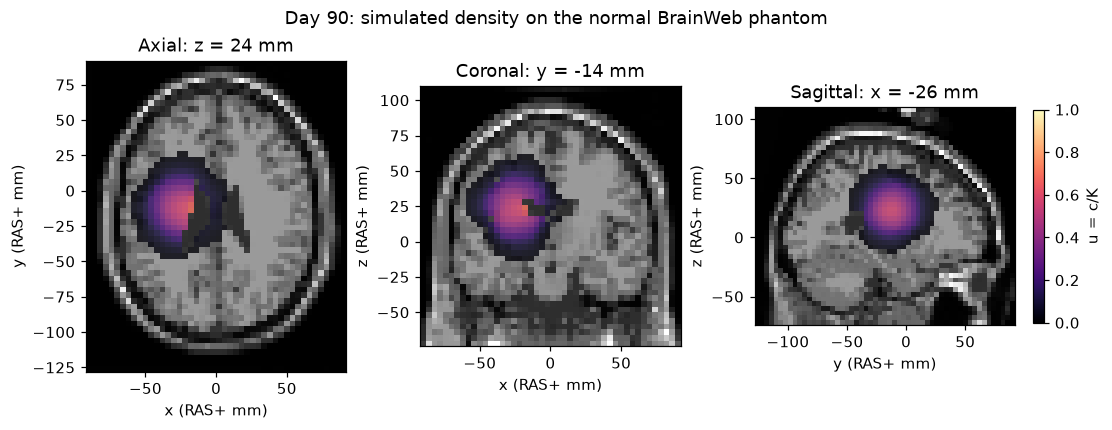

In [4]:
show_figure(lessons.plot_brainweb(brain, runs), 'orthogonal-views')

## 4. Calculate two distinct volumetric quantities

For voxel volume $v=\Delta x\Delta y\Delta z$ in mm³:

$$B(t)=\frac{v}{1000}\sum_i u_i(t),\qquad V_\tau(t)=\frac{v}{1000}\sum_i\mathbf{1}[u_i(t)\geq\tau].$$

The indicator $\mathbf{1}[u_i\geq\tau]$ equals one when voxel $i$ meets threshold $\tau$, and zero otherwise. Both have units mL, but $B$ is a **normalized burden** and $V_\tau$ a threshold volume. The former weights every voxel by density fraction; the latter counts selected voxels equally. Neither is an absolute cell count. If a suitable constant $K$ in cells/mm³ were actually known, $1000KB$ would be a model-implied cell count.

At 4 mm spacing, one voxel occupies 64 mm³ = 0.064 mL. A voxel at $u=0.25$ contributes 0.016 mL to normalized burden, and 0.064 mL to $V_{0.2}$. There is no calibrated mapping from this threshold to MRI enhancement or FLAIR.

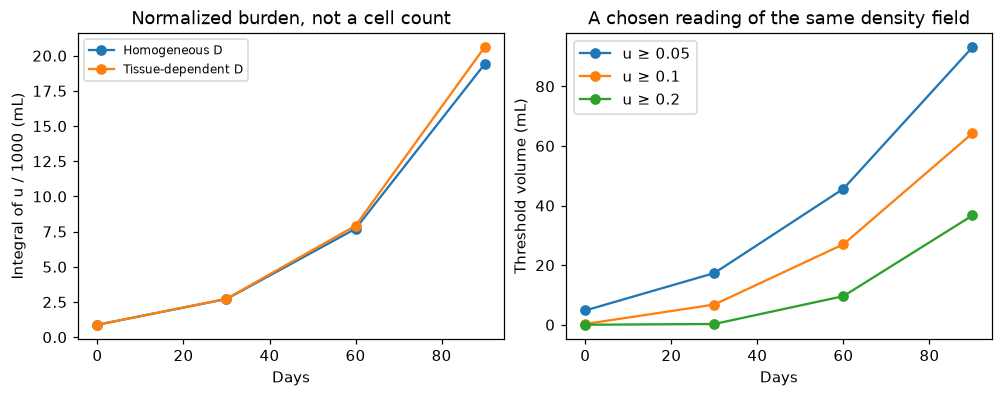

Day-90 volume at u >= 0.05: 93.120 mL
Day-90 volume at u >= 0.1: 64.256 mL
Day-90 volume at u >= 0.2: 36.672 mL
Day-90 normalized burden: 20.603 mL


In [5]:
show_figure(lessons.plot_anatomical_measures(runs), 'burden-and-threshold-volumes')
run = runs['Tissue-dependent D']
for threshold in [.05, .1, .2]:
    print(f'Day-90 volume at u >= {threshold}: {run.threshold_measure(threshold)[-1]:.3f} mL')
print('Day-90 normalized burden:', round(run.integral[-1], 3), 'mL')

## 5. Check the numerical accounting

The diffusion update should add and remove exactly the same amount across each internal face. With growth enabled, the final integral minus its initial value should equal the accumulated reaction gain, up to floating-point error. Outside-domain density should remain zero. These checks assess implementation accounting; an incorrect biological model could still pass them.

In [6]:
for label, run in runs.items():
    np.testing.assert_allclose(run.integral-run.integral[0], run.reaction_gain, atol=1e-10)
    np.testing.assert_array_equal(run.density[:, ~brain.domain], 0.)
    assert run.density.min() >= -1e-12 and run.density.max() <= 1+1e-12
    print(label, '| balance residual:', run.balance_error,
          '| actual max dt:', run.largest_step, '| limit:', run.step_limit, 'days')
record = {'data_commit': COMMIT, 'spacing_mm': brain.spacing_mm,
          'shape': brain.labels.shape, 'origin_ras_mm': lessons.ORIGIN,
          'D_WM_mm2_day': .5, 'D_GM_mm2_day': .1, 'rho_per_day': .04,
          'evidence': 'assigned-parameter growth on a normal digital phantom'}
(OUTPUT / 'provenance.json').write_text(json.dumps(record, indent=2)+'\n')
print('Saved parameters and data provenance.')

Homogeneous D | balance residual: 7.105427357601002e-15 | actual max dt: 1.0 | limit: 9.91125651569269 days
Tissue-dependent D | balance residual: 3.552713678800501e-15 | actual max dt: 1.0 | limit: 5.333333333333333 days
Saved parameters and data provenance.


## Interactive experiment: parameters, sampled anatomy and image views

Press **Run 3-D simulation** after selecting tissue diffusivities, proliferation rate, requested time step and grid spacing. The 2 mm option uses more memory and CPU time than 4 or 6 mm. The actual time step and its stability bound are reported; an invalid request is rejected, not repaired silently. Changing grid spacing also changes represented tissue geometry.

The view controls read cached states: choose a day, density threshold, orthogonal slice coordinates and overlay opacity. Slice titles show the nearest sampled RAS+ coordinate. Threshold and opacity alter the display, not the simulated field. The widget starts at a density threshold of 0.1; the fixed overlay above uses 0.01, so their initial displayed extents differ. The reported threshold volume counts the full 3-D field, not only the displayed slices. Pending simulation changes are identified until you press Run again.

**Try:** vary only the grey-matter diffusivity and inspect shape and burden. Then keep the run fixed and vary threshold and slice position. Finally compare 4 and 6 mm sampling: which thin barriers change?

All anatomy is bundled with this repository. Widgets require a live notebook kernel; GitHub retains the static reference figures above. Interactive results do not overwrite the paper figures.

In [7]:
from IPython.display import display
from brainsmodels.growth_widgets import brainweb_explorer

explorer = brainweb_explorer()
display(explorer.widget)

## 6. Interpretation and questions

The comparison establishes consequences of specified coefficient maps on specified sampled anatomy. It does not calibrate tissue motility, infer an actual tumour from T1, or validate an individual forecast. Thin barriers may be under-resolved at 4 mm, and the closed-CSF assumption remains a modelling choice.

**Takeaway:** anatomy supplies geometry and context; it does not supply tumour parameters or an observation model.

**Check question:** which part of the image above is source data, which part is a model state, and which part is a display rule?

### Exercises

1. Increase only the display threshold. What remains invariant?
2. Repeat with `step_mm=2`, keeping physical seed coordinates and coefficients fixed. Why is a difference not purely a time-stepping error?
3. Which independent measurements would be needed to estimate the two tissue dispersal rates rather than assign them?

<details><summary><strong>Show reasoning</strong></summary>

1. The density field, its integral, anatomy and parameters stay unchanged. Only the selected volume/boundary changes.
2. The represented tissue geometry also changes, including thin structures and seed sampling. Compare time steps on a fixed grid separately from anatomy/grid sensitivity.
3. Serial, spatially resolved observations with a justified mapping to cell density, initialization, tissue geometry, treatment information and uncertainty would be needed. Whether they identify both rates is an additional question, not guaranteed by having many voxels.

</details>

## Further reading and data attribution

- [BrainWeb simulated brain database](https://brainweb.bic.mni.mcgill.ca/brainweb/) and [original normal anatomical model](https://brainweb.bic.mni.mcgill.ca/anatomic_normal.html).
- [Collins et al. (1998), Design and construction of a realistic digital brain phantom](https://doi.org/10.1109/42.712135).
- Cocosco et al. (1997), *BrainWeb: Online Interface to a 3D MRI Simulated Brain Database*, NeuroImage 5(4), S425.
- [Bundled data manifest](https://github.com/arvidl/brains-to-models/blob/main/code/src/brainsmodels/data/brainweb/manifest.json) and [full external explorer](https://github.com/arvidl/brainweb_fisher_kpp/blob/81ecd42e6f37692a711208caa8d24361904f7e65/tumor_growth_explorer.ipynb). That explorer includes additional model and rendering options; this notebook does not reproduce its complete implementation.

Continue with [14c: fitting generated observations and withholding a forecast](https://github.com/arvidl/brains-to-models/blob/main/code/notebooks/14c_growth_parameter_recovery.ipynb).